In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
# standardize the data
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# visualizations
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score

# data loader
from torch.utils.data import DataLoader, Dataset

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

In [2]:
# # prepare the data
train_df = pd.read_csv('../datasets/train_data.csv').drop('Unnamed: 0', axis=1)
test_df = pd.read_csv('../datasets/test_data.csv').drop('Unnamed: 0', axis=1)

# standardize the data
scaler = StandardScaler()

X_train = train_df.drop('machine_state', axis=1).values
X_train = scaler.fit_transform(X_train)

y_train = train_df['machine_state'].values

X_test = test_df.drop('machine_state', axis=1).values
X_test = scaler.transform(X_test)

y_test = test_df['machine_state'].values


In [3]:
# # standardize the data
# scaler = StandardScaler()
# 
# complete_df = pd.read_csv('../datasets/complete.csv')
# X_train = complete_df.drop('machine_state', axis=1).values
# X_train = scaler.fit_transform(X_train)
# y_train = complete_df['machine_state'].values
# X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [4]:
# Convert the data to PyTorch tensors
X_train = torch.FloatTensor(X_train)
y_train = torch.FloatTensor(y_train)
X_test = torch.FloatTensor(X_test)
y_test = torch.FloatTensor(y_test)


y_train = y_train.unsqueeze(1)
y_test = y_test.unsqueeze(1)


In [5]:
# # tensors to device
# X_train = X_train.to(device)
# y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)


In [6]:
train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)
#
# test_dataset = torch.utils.data.TensorDataset(X_test, y_test)
# test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

In [7]:
# Define the model
class FeedForward(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FeedForward, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.5)
        #
        self.fc2 = nn.Linear(hidden_dim, 32)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.3)

        self.fc3 = nn.Linear(32, output_dim)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu1(out)
        out = self.dropout1(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.dropout2(out)
        out = self.fc3(out)
        out = self.sigmoid(out)
        return out

# early stopping
class EarlyStopping:
    def __init__(self, patience=10, verbose=False, delta=0):
        """
        :param patience: How long to wait after last time validation loss improved.
        :param verbose: If True, prints a message for each validation loss improvement.
        :param delta: Minimum change in the monitored quantity to qualify as an improvement.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0 # counter for the number of epochs with no improvement
        self.best_score = None # the best score so far
        self.early_stop = False # whether to stop the training
        self.val_loss_min = np.Inf # the minimum validation loss
        self.delta = delta

    def __call__(self, val_loss, model):
        score = -val_loss # the score is the negative of the validation loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model...')
        torch.save(model.state_dict(), 'checkpoint.pt')
        self.val_loss_min = val_loss


def validate(val_model, val_x, val_y, val_criterion):
    val_model.eval()
    val_total_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        val_outputs = val_model(val_x)
        val_loss = val_criterion(val_outputs, val_y)
        val_total_loss += val_loss.item()

        val_predicted = val_outputs.round()
        val_correct += val_predicted.eq(val_y).sum().item()
        val_total += val_y.size(0)

        val_epoch_loss = val_total_loss / val_total
        val_epoch_acc = val_correct / val_total
        val_epoch_f1 = f1_score(val_y.cpu().numpy(), val_predicted.cpu().numpy())

    return val_epoch_loss, val_epoch_acc, val_epoch_f1





In [8]:
# Instantiate the model
input_dimensions = X_train.shape[1]
hidden_dimensions = 64
output_dimensions = 1
model = FeedForward(input_dimensions, hidden_dimensions, output_dimensions)
model.to(device)


FeedForward(
  (fc1): Linear(in_features=39, out_features=64, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

In [9]:
criterion = nn.BCELoss()

# optim = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.1)
optim = optim.SGD(model.parameters(), lr=0.001, momentum=0.8, weight_decay=0.1 )

early_stopping = EarlyStopping(patience=10, verbose=True)


Epoch: 1, Loss: 3.939200818410744e-05, Accuracy: 0.4118942731277533, F1 Score: 0.2713595969491288
Validation loss decreased (inf --> 0.000039). Saving model...
Epoch: 2, Loss: 3.928633499964205e-05, Accuracy: 0.4548175759629504, F1 Score: 0.30116556866719757
Validation loss decreased (0.000039 --> 0.000039). Saving model...
Epoch: 3, Loss: 3.918481252832519e-05, Accuracy: 0.49830565909861063, F1 Score: 0.3327574551190566
Validation loss decreased (0.000039 --> 0.000039). Saving model...
Epoch: 4, Loss: 3.908832612097445e-05, Accuracy: 0.5356376369592228, F1 Score: 0.3612492231199503
Validation loss decreased (0.000039 --> 0.000039). Saving model...
Epoch: 5, Loss: 3.9000609062976464e-05, Accuracy: 0.5661922512142776, F1 Score: 0.392374021042639
Validation loss decreased (0.000039 --> 0.000039). Saving model...
Epoch: 6, Loss: 3.8914322704968854e-05, Accuracy: 0.5889528973229414, F1 Score: 0.4180393411162642
Validation loss decreased (0.000039 --> 0.000039). Saving model...
Epoch: 7, Lo

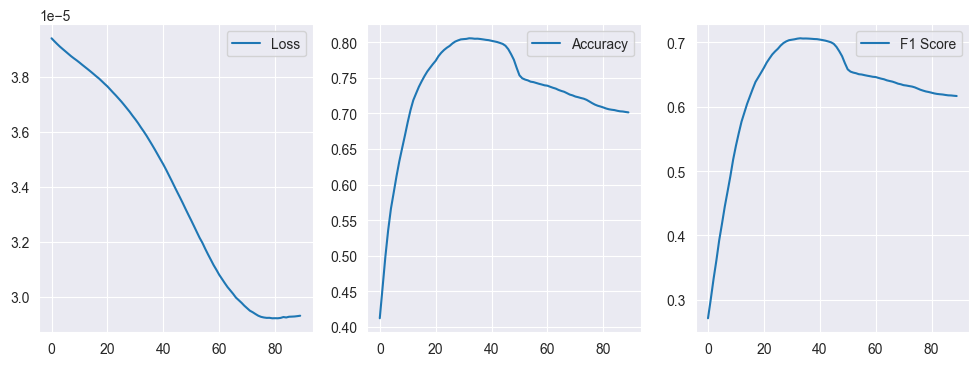

In [10]:
# Train the model
epochs = 100

# storing metrics
losses = []
accuracies = []
f1_scores = []

for epoch in range(epochs):
    total_loss = 0
    correct = 0
    total = 0

    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        outputs = model(data)
        loss = criterion(outputs, target)
        total_loss += loss.item()

        # accuracy
        predicted = outputs.round()
        # correct += predicted.eq(target).sum().item()
        total += target.size(0)

        # backpropagation
        optim.zero_grad()
        loss.backward()
        optim.step()

    # validation
    epoch_loss, epoch_acc, epoch_f1 = validate(model, X_test, y_test, criterion)
    print(f'Epoch: {epoch+1}, Loss: {epoch_loss}, Accuracy: {epoch_acc}, F1 Score: {epoch_f1}')

    # Append metrics to the lists
    losses.append(epoch_loss)
    accuracies.append(epoch_acc)
    f1_scores.append(epoch_f1)

    # early stopping
    early_stopping(epoch_loss, model)
    if early_stopping.early_stop:
        print('Early stopping has been triggered.')
        break


# Plot the metrics
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(losses, label='Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(accuracies, label='Accuracy')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(f1_scores, label='F1 Score')
plt.legend()

plt.show()

In [11]:
# Load the best model
model.load_state_dict(torch.load('checkpoint.pt'))

# Evaluate the model
model.eval()
with torch.no_grad():
    outputs = model(X_test)
    loss = criterion(outputs, y_test)
    predicted = outputs.round()
    correct = predicted.eq(y_test).sum().item()
    total = y_test.size(0)
    accuracy = correct / total
    f1 = f1_score(y_test.cpu().numpy(), predicted.cpu().numpy())
    print(f'Loss: {loss.item()}, Accuracy: {accuracy}, F1 Score: {f1}')

Loss: 0.5173079371452332, Accuracy: 0.709815881622049, F1 Score: 0.622926757669162


In [12]:
# Save the model
# torch.save(model.state_dict(), 'feedforward_model.pt')



In [13]:
# Load the model

In [14]:
predicted = predicted.cpu().numpy()


In [15]:
# add the predicted values to the test data
test_df['predicted'] = predicted


In [16]:
test_df[['Frequency L2 Current', 'machine_state', 'predicted']]

,Frequency L2 Current,machine_state,predicted
0,15.0,1,1.0
1,15.0,1,1.0
2,15.0,1,1.0
3,15.0,1,1.0
4,15.0,1,1.0
...,...,...,...
17701,20.0,0,0.0
17702,20.0,0,0.0
17703,20.0,0,0.0
17704,1.0,0,1.0


In [17]:
# for every frequency, get the number of equal values between machine state and predicted
test_df.groupby('Frequency L2 Current').apply(lambda x: (x['machine_state'] == x['predicted']).sum(), include_groups=False)

Frequency L2 Current
0.5        1
1.0        0
1.5        0
2.0        0
2.5        0
3.0        7
3.5        1
6.5        0
7.0        1
7.5        0
9.5        0
10.0       2
10.5       0
11.0       2
15.0    3659
15.5       0
16.5       0
17.0    4636
18.0       0
18.5       0
19.0       1
19.5       3
20.0     410
20.5       1
24.5       0
25.0    3227
30.0     572
35.0      45
dtype: int64

In [18]:
# for each frequency, get the number of times the machine was in a state where machine state and predicted are different
test_df.groupby('Frequency L2 Current').apply(lambda x: (x['machine_state'] != x['predicted']).sum(), include_groups=False)


Frequency L2 Current
0.5      171
1.0      242
1.5      191
2.0        7
2.5       32
3.0      161
3.5       66
6.5        2
7.0        6
7.5        8
9.5        4
10.0    1119
10.5       1
11.0    1047
15.0      33
15.5       2
16.5       2
17.0    1981
18.0       2
18.5       1
19.0       2
19.5       1
20.0       0
20.5       0
24.5       1
25.0      56
30.0       0
35.0       0
dtype: int64

In [19]:
# create a new frequency column if Frequency L2 Current is greater than 25 high, lower than 25 and higher
